In [29]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [23]:
dados = pd.read_parquet("../outputs/dadosEscolaLimpos.parquet")

In [ ]:
y = dados['vResposta']
x = dados.drop(columns=['vResposta'])


categoricas = x.select_dtypes(include=['object', 'category']).columns
numericas = x.select_dtypes(include=['number']).columns

In [ ]:
pipeCategoricas = Pipeline([
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=47) #Dividindo o dataset entre conjunto de treino e conjunto de teste, usando a seed random_state=100

In [26]:
modelo = LogisticRegression() #Definindo o modelo

In [ ]:
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)








auc = roc_auc_score(y_test, y_pred)
print(f"ROC AUC: {auc:.4f}")

ValueError: could not convert string to float: 'CentroOeste'

In [ ]:
y_pred_arredondado = np.round(y_pred).astype(int) #Arredondando os valores
y_test_int = y_test.astype(int)
print("Acurácia: ", accuracy_score(y_test_int, y_pred_arredondado)) #Calculando a acurácia

Acurácia:  0.6104166666666667


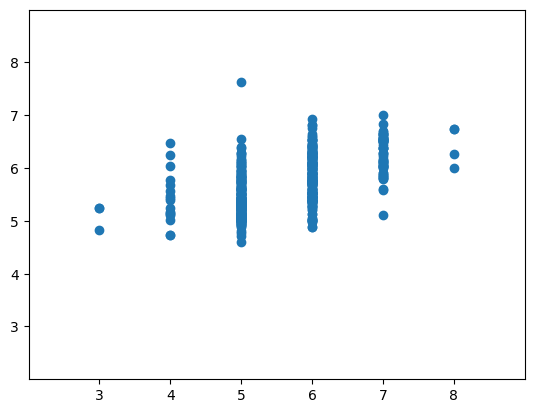

In [ ]:
import numpy as np #Criar o gráfico bonitinho
import matplotlib.pyplot as plt

fig, ax = plt.subplots (1, 1)
ax.set_xlim([2,9])
ax.set_ylim([2,9])
_ = ax.set_xticks([3, 4, 5, 6, 7, 8])
_ = ax.set_yticks([3, 4, 5, 6, 7, 8])


_ = ax.scatter(y_test, y_pred) #Valores contínuos

Acurácia: 0.8479166666666667
              precision    recall  f1-score   support

        ruim       0.00      0.00      0.00        20
     regular       0.87      0.96      0.91       397
         bom       0.63      0.38      0.48        63

    accuracy                           0.85       480
   macro avg       0.50      0.45      0.46       480
weighted avg       0.80      0.85      0.82       480



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


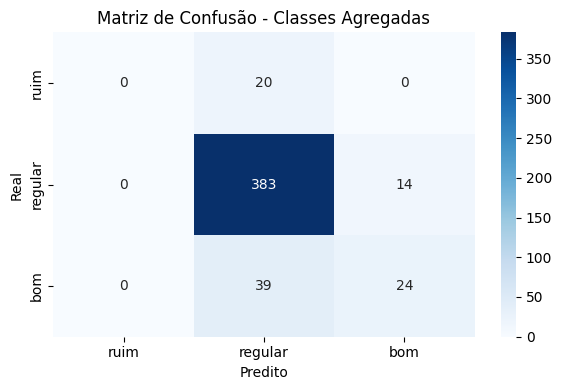

In [ ]:
# Agrupando em 3 classes
# 2. Função de mapeamento de notas para classes
def agrupar_classe(nota):
    if nota in [3, 4]:
        return 1  # ruim
    elif nota in [5, 6]:
        return 2  # regular
    elif nota in [7, 8]:
        return 3  # bom
    else:
        return np.nan  # segurança extra, caso apareça valor fora do intervalo

# 3. Aplicar mapeamento
y_pred_agregado = np.array([agrupar_classe(n) for n in y_pred_arredondado])
y_test_agregado = np.array([agrupar_classe(n) for n in y_test_int])

# 4. Avaliação
print("Acurácia:", accuracy_score(y_test_agregado, y_pred_agregado))

# Relatório de classificação
print(classification_report(y_test_agregado, y_pred_agregado, target_names=['ruim', 'regular', 'bom']))

# Matriz de Confusão
cm = confusion_matrix(y_test_agregado, y_pred_agregado, labels=[1, 2, 3])

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['ruim', 'regular', 'bom'],
            yticklabels=['ruim', 'regular', 'bom'])
plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusão - Classes Agregadas')
plt.tight_layout()
plt.show()